# Projeto 01 — Agente de recolha e entrega de alimentos locais

**Fundamentos de Inteligência Artificial** · Mestrado em Inteligência Artificial Aplicada, 2026-27 · **Grupo G09**

| Nome | Número |
|---|---|
| _(preencher)_ | _(preencher)_ |
| _(preencher)_ | _(preencher)_ |

## 1. Introdução

Uma plataforma digital liga **pequenos produtores** do distrito de Braga (e Póvoa de Varzim), **clientes**
e um **centro de recolha** com frota própria. Cada produto segue o fluxo
**produtor → centro de recolha → local de entrega**: é recolhido no produtor dentro da sua janela de
disponibilidade, descarregado no centro, carregado mais tarde e entregue ao cliente dentro da janela de
entrega.

O objetivo é desenvolver o **agente de planeamento de rotas** da plataforma. O agente escolhe, para cada
veículo, a sequência de viagens que serve todas as encomendas **ao menor número de quilómetros**, e
respeita as seguintes restrições:

* janelas de recolha e de entrega (limitam o *início* do serviço);
* capacidade de cada veículo;
* passagem obrigatória pelo armazém, com 15 min para descarregar e 15 min para carregar, e no máximo
  24 h de permanência;
* 10 min de serviço em cada paragem.

O agente é resolvido com as três famílias de técnicas pedidas no enunciado:

1. **pesquisa informada**: Greedy best-first e A\*, com quatro heurísticas e duas formulações
   (paragem a paragem e viagem a viagem);
2. **pesquisa local**: Hill Climbing (duas variantes) e Simulated Annealing;
3. **problemas de satisfação de restrições (CSP)**: backtracking com MRV, ordenação de valores,
   forward checking e AC-3.

Este notebook reúne todo o trabalho. Os notebooks auxiliares têm as experiências detalhadas:

* [`02_eda_tiny.ipynb`](02_eda_tiny.ipynb): análise exploratória;
* [`03_informed.ipynb`](03_informed.ipynb): pesquisa informada;
* [`04_local_search.ipynb`](04_local_search.ipynb): pesquisa local;
* [`05_csp.ipynb`](05_csp.ipynb): CSP.

Estrutura do repositório:

```
data/tiny, data/small      CSV originais
src/model.py               entidades, carregamento, simulador, custo, verificação de viabilidade,
                           auditoria dos dados, verificador linha a linha e figuras
src/informed.py            Greedy, A*, A* ponderado, A* por viagens e heurísticas h1–h4
src/local_search.py        Hill Climbing e Simulated Annealing
src/csp.py                 formulação CSP, backtracking, FC, AC-3
run_experiments.py         corre todas as experiências e grava reports/
tests/                     testes unitários
```

In [1]:
import sys, json, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd

from src.model import load_problem, evaluate, schedule_table, State, PICKUP, DELIVERY
from src.model import audit, read_tables, check_solution
from src.informed import (greedy, astar, astar_trips, weighted_astar, catalog, HEURISTICS,
                          h_max_detour, h_min_arcs, h_mst, h_relaxed)
from src.local_search import hill_climbing, simulated_annealing
from src.csp import solve, RoutingCSP, TEMPLATE
from src.model import plot_locations, plot_routes, plot_gantt, plot_histories

pd.set_option("display.max_columns", 30); pd.set_option("display.width", 170)
ROOT = Path.cwd().parent
REPORTS = ROOT / "reports"
RUN_HEAVY = False   # True: volta a correr as pesquisas longas (A* exato demora minutos); False: lê reports/
tiny = load_problem(ROOT / "data" / "tiny")
small = load_problem(ROOT / "data" / "small")

## 2. Análise exploratória de dados

A análise completa está em [`02_eda_tiny.ipynb`](02_eda_tiny.ipynb). Aqui fica o essencial.

In [2]:
T = {ds: read_tables(ROOT / "data" / ds) for ds in ("tiny", "small")}
summary = pd.DataFrame({ds: dict(
    encomendas=len(t["orders"]), linhas=len(t["order_items"]), produtores=len(t["producers"]),
    locais_entrega=len(t["delivery_locations"]), veiculos=len(t["vehicles"]),
    capacidade_kg=" + ".join(f"{c:.0f}" for c in t["vehicles"].capacity_kg),
    procura_kg=round(t["order_items"].weight_kg.sum(), 1)) for ds, t in T.items()})
summary

,tiny,small
encomendas,12,25
linhas,40,80
produtores,3,6
locais_entrega,5,7
veiculos,2,2
capacidade_kg,150 + 200,250 + 300
procura_kg,270.0,580.0


In [3]:
a = pd.concat([audit(t).assign(dataset=ds) for ds, t in T.items()])
a.pivot_table(index="status", columns="dataset", values="check", aggfunc="count", fill_value=0)

dataset,small,tiny
status,,
info,2,2
ok,67,67


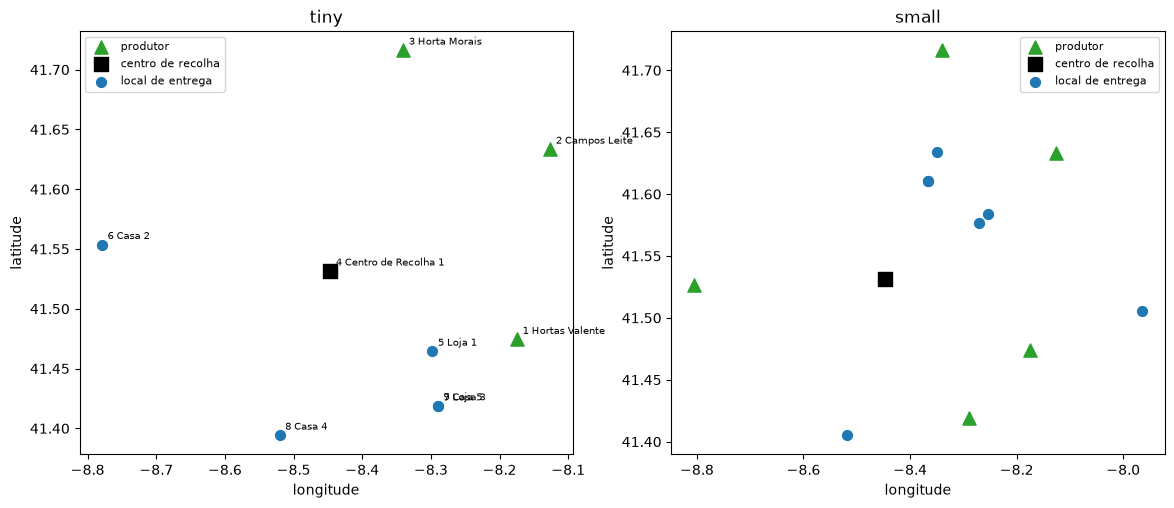

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
plot_locations(tiny, ax[0]); ax[0].set_title("tiny")
plot_locations(small, ax[1], labels=False); ax[1].set_title("small");

**Conclusões principais da EDA**

* **Integridade:** os dados estão íntegros. As 67 verificações da auditoria passam nos dois datasets.
  Há dois pontos apenas informativos: alguns locais de entrega partilham coordenadas, e nenhuma linha foi
  encomendada depois de abrir a sua janela de recolha.
* **Restrições que apertam:** são as **temporais**, não a capacidade. No tiny, as recolhas são de manhã
  (06:45–12:15) e as entregas a meio do dia. Três encomendas são recolhidas no dia 30 e entregues no dia
  31, com 25–29 h entre abrir a recolha e fechar a entrega. Aqui o limite de 24 h no armazém passa a
  contar.
* **Geografia:** o centro fica entre os produtores (a leste) e os clientes (oeste e sul), a 19–38 km de
  cada local. Cada viagem é uma ida e volta ao centro, por isso o **número de viagens** domina o custo.
* **Capacidade no small:** a procura (580 kg) excede a capacidade da frota (550 kg), por isso são
  obrigatórias várias viagens por veículo.

## 3. Modelação

### 3.1 Decisões de modelação

| Decisão | Justificação |
|---|---|
| Tempo em minutos desde `start_date 00:00` | Simplifica as contas. As datas só são usadas para mostrar resultados. |
| **Pedido de recolha** = linhas do mesmo produtor cujas janelas se intersetam (*interval stabbing*), limitado à capacidade do menor veículo | Uma paragem recolhe tudo o que está disponível ao mesmo tempo. No tiny passa-se de 40 linhas para 6 recolhas. |
| **Pedido de entrega** = uma encomenda | Todas as linhas de uma encomenda têm o mesmo destino e a mesma janela. |
| Janela de recolha começa em `max(availability_start, order_datetime)` | Não se recolhe um produto antes de o cliente o encomendar. |
| Uma rota é uma lista de **viagens**, cada uma sai e volta ao centro | Decorre do fluxo produtor → armazém → cliente. |
| Viagens **homogéneas**: só recolhas ou só entregas | Simplifica a precedência: o que foi recolhido numa viagem só fica disponível no armazém quando ela termina. |
| Nenhuma viagem atravessa a meia-noite | Sem esta regra, um veículo podia ficar à noite parado num cliente à espera da janela do dia seguinte. |
| Partida *just in time* | Chega-se à primeira paragem quando a janela abre. Reduz a espera e a permanência no armazém. |
| Transferência entre veículos permitida no armazém | Um veículo pode entregar o que outro recolheu, desde que já esteja descarregado. |
| Objetivo: minimizar os **km totais** | O tempo de rota e o *makespan* são reportados como métricas secundárias. |
| Refrigeração ignorada | Os dados não indicam que produtos precisam de frio. |

### 3.2 Classes principais (`src/model.py`)

* `Item`: uma linha de encomenda, com peso, janela de disponibilidade e janela de entrega.
* `Request`: o que o agente tem de agendar. É uma recolha (grupo de linhas de um produtor) ou uma entrega
  (uma encomenda), e tem local, janela, peso e, nas entregas, as recolhas de que depende (`deps`).
* `Vehicle`: capacidade, refrigeração e velocidade.
* `Problem`: a instância, com pedidos, frota, centro, matriz de distâncias e tempos, e regras.
* `State` / `VState`: o nó da pesquisa informada, uma solução parcial construída viagem a viagem.
* `Solution`: `{veículo: [viagem, viagem, ...]}`, em que cada viagem é uma lista de pedidos.

### 3.3 Função de custo e verificação de viabilidade

`evaluate(problem, solution)` simula todas as viagens e devolve os km e todas as violações: atraso
(min), excesso de carga (kg), excesso de permanência (min), pedidos em falta ou duplicados, bloqueios e
viagens que atravessam a noite. As viagens de veículos diferentes interagem através do armazém: uma
viagem de entrega só começa a carregar depois de descarregadas todas as recolhas de que depende. Por
isso a simulação é **dirigida por dependências**: avança o veículo cuja viagem seguinte já tem tudo
disponível. Se nenhum veículo conseguir avançar, a solução está bloqueada (dependência circular).

Para a pesquisa local usa-se o custo penalizado: `km + 100·(atraso + excesso + permanência) + 10 000·(erros estruturais)`.

In [5]:
rows = [dict(id=r, tipo=q.kind, local=q.loc, janela=f"{tiny.clock(q.tw[0])} – {tiny.clock(q.tw[1])}",
             kg=q.weight, linhas=len(q.items), depende_de=", ".join(q.deps)) for r, q in tiny.requests.items()]
pd.DataFrame(rows).set_index("id").T

id,P1,P2,P3,P4,P5,P6,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10,D11,D12
tipo,P,P,P,P,P,P,D,D,D,D,D,D,D,D,D,D,D,D
local,1,1,2,2,3,3,7,8,6,7,5,7,9,6,9,8,5,6
janela,30 09:30 – 30 09:45,31 09:00 – 31 11:15,30 09:00 – 30 10:30,31 08:15 – 31 10:00,30 08:00 – 30 09:45,31 07:45 – 31 09:45,31 10:30 – 31 12:45,31 07:15 – 31 10:15,31 11:30 – 31 14:15,30 11:30 – 30 13:45,31 10:30 – 31 12:30,31 10:45 – 31 13:15,31 10:45 – 31 13:30,31 09:30 – 31 12:00,31 08:15 – 31 09:45,30 11:45 – 30 14:00,30 10:15 – 30 14:00,30 12:15 – 30 14:45
kg,52.0,41.1,77.6,29.9,37.3,32.1,22.0,6.8,21.6,26.3,9.3,16.7,33.5,18.8,36.7,9.2,18.0,51.1
linhas,8,5,9,5,7,6,4,2,4,3,2,2,4,3,5,2,4,5
depende_de,,,,,,,"P2, P4, P6","P1, P5","P2, P4, P6","P1, P3, P5","P4, P6","P4, P6","P2, P4","P3, P5","P1, P3, P5","P1, P3","P1, P3, P5","P1, P3"


In [6]:
# exemplo: uma solução escrita à mão e uma variante inválida
manual = {1: [["P4", "P6", "P2"], ["D3"]],
          2: [["P5", "P1", "P3"], ["D4", "D11", "D10", "D12"], ["D2", "D9", "D8"], ["D1", "D6", "D5", "D7"]]}
broken = {1: [["D3"], ["P4", "P6", "P2"]], 2: manual[2]}           # entrega antes da recolha
pd.DataFrame({"manual": evaluate(tiny, manual).summary(), "invalida": evaluate(tiny, broken).summary()})

,manual,invalida
km,663.81,397.58
feasible,True,False
trips,6,3
late_min,0.0,0.0
over_kg,0.0,0.0
dwell_excess_min,0.0,0.0
unserved,0,0
deadlock,0,8
overnight,0,0
makespan_min,2243.5,2078.5


### 3.4 Verificador independente, linha a linha (`check_solution` em `src/model.py`)

Para não confiar só no simulador usado pelos algoritmos, cada solução é convertida numa lista explícita
de paragens (`pickup`, `unload`, `load`, `delivery`, `return`), com as linhas individuais. Essa lista é
depois verificada contra os **CSV originais**, sem usar os pedidos agregados. O verificador confirma:

* tempos de viagem e janelas por linha, incluindo `order_datetime`;
* carga ao longo da rota;
* que cada linha é recolhida, descarregada, carregada e entregue exatamente uma vez;
* que só se carrega depois de descarregar, e a permanência máxima;
* o regresso ao centro, o horizonte e a capacidade do armazém.

Este verificador vem do protótipo anterior do grupo e foi adaptado a este código.

In [7]:
ev = evaluate(tiny, manual)
chk = check_solution(tiny, ev)
print("simulador:", round(ev.km, 2), "km, viável =", ev.feasible, "| verificador por linha:", chk.valid, round(chk.km, 2), "km")
print("solução inválida ->", check_solution(tiny, evaluate(tiny, broken)).errors[:3])

simulador: 663.81 km, viável = True | verificador por linha: True 663.81 km
solução inválida -> ['line 1: pickup done 0 times (expected 1)', 'line 1: unload done 0 times (expected 1)', 'line 1: load done 0 times (expected 1)']


## 4. Pesquisa informada

Experiências detalhadas em [`03_informed.ipynb`](03_informed.ipynb).

### 4.1 Formulação como problema de pesquisa

* **Estado:** solução parcial. Para cada veículo guarda o local, o relógio, a viagem aberta (tipo e
  pedidos) e as viagens já fechadas. Guarda também o conjunto de pedidos servidos e a hora a que cada
  recolha chegou ao armazém.
* **Estado inicial:** os dois veículos parados no centro, às 00:00 do dia 30, sem pedidos servidos.
* **Ações** (sobre um veículo de cada vez):
  * *visitar* um pedido por servir, compatível com a viagem aberta, ou abrir uma viagem nova;
  * *fechar* a viagem aberta, voltando ao centro.

  Uma entrega só pode ser visitada depois de todas as suas recolhas estarem no armazém. Os filhos que
  violam janela, capacidade, permanência ou a regra da meia-noite são descartados.
* **Objetivo:** todos os pedidos servidos e os dois veículos no centro.
* **Custo do caminho g:** km percorridos até ao momento.
* **Podas exatas**, que nunca eliminam uma solução viável:
  * *beco sem saída*: um pedido que, mesmo nas condições mais otimistas, já não pode começar dentro da
    janela. Para as entregas usa-se também o primeiro momento em que as suas recolhas podem estar no
    armazém;
  * *dominância*: entre dois estados com os mesmos pedidos e as mesmas viagens abertas, descarta-se o
    que tem maior custo e relógios mais tardios. A comparação das horas de chegada ao armazém só é usada
    quando o limite de 24 h nunca pode ser violado; caso contrário exige-se igualdade, para a poda
    continuar exata.

### 4.1b Segunda formulação: uma ação = uma viagem completa

Na formulação anterior, a mesma solução pode ser construída por muitas sequências de ações (paragem a
paragem, alternando veículos, ordens diferentes). Na segunda formulação, **todos os veículos estão no
centro entre ações**, e cada ação é *"o veículo v faz a viagem T"*:

* **Catálogo de viagens:** antes da pesquisa, enumeram-se todas as viagens que *podem* fazer parte de
  uma solução (conjunto de pedidos + ordem). Usa-se a partida mais cedo possível de cada grupo: uma
  partida mais tarde só pode tornar uma viagem inviável, nunca o contrário.
* **Horário em forma fechada:** para uma ordem fixa, o regresso ao centro é `max(D + δ, c)`, onde D é
  a hora de partida, δ a duração sem esperas e c o regresso mais cedo forçado pelas janelas. A viagem
  é viável se `D ≤ Dmax`.
* **Redução exata:** entre duas ordens do mesmo conjunto, descarta-se a que é pior ou igual em km, δ, c,
  Dmax e hora de carregar, porque é pior para qualquer hora de partida e qualquer continuação.
* **Ação:** a viagem é testada no contexto real (veículo livre, hora real a que as recolhas chegaram ao
  armazém, capacidade do veículo, 24 h, meia-noite), com as mesmas regras do simulador. Um teste
  unitário confirma que o horário calculado coincide com o do simulador.

O estado, o custo, o objetivo, as podas e as heurísticas são os mesmos; muda só o tamanho do passo. Um
"nó expandido" passa a ser "uma viagem acrescentada".

### 4.2 Heurísticas (todas admissíveis: limites inferiores dos km que faltam)

* **h1, desvio máximo**: max sobre pedidos por servir de [distância do veículo mais próximo até ao
  pedido + distância do pedido ao centro]. Pela desigualdade triangular, nenhum completamento é mais
  curto. É simples e fraca.
* **h2, arcos mínimos**: agrupa os pedidos por nó (local, dia, tipo); só nós do mesmo dia e tipo podem
  partilhar uma viagem. Cada nó por servir precisa de um arco de entrada (do centro, de outro nó do grupo
  ou de um veículo com viagem aberta desse grupo), e cada viagem ainda necessária precisa de um arco de
  regresso. Soma os mínimos.
* **h3, MST por grupo**: retirando o arco de regresso a cada viagem que falta, o que sobra liga o centro
  a todos os nós por servir, logo custa pelo menos uma **árvore de cobertura mínima**. Junta-se um limite
  do tipo *1-tree* e conta-se o número mínimo de viagens por grupo. Esse número sai do peso e de pares
  de pedidos incompatíveis: janelas que não se encadeiam, ou entregas cujos produtos ficam prontos tarde
  demais para a outra.
* **h4, relaxação exata por grupo**: em cada grupo (dia, tipo) resolve-se **de forma exata** um problema
  mais simples. Há veículos ilimitados com a capacidade do maior, e as entregas saem logo que os produtos
  podem estar no armazém, no caso mais otimista. Mantêm-se as janelas, os tempos de serviço e de
  carga/descarga, a capacidade e a regra da meia-noite. Primeiro enumeram-se as viagens possíveis do
  grupo; depois escolhe-se, por programação dinâmica sobre subconjuntos, a combinação de viagens mais
  barata que cobre os pedidos por servir. Como o problema real tem mais restrições, não pode custar
  menos. Com viagens abertas, subtrai-se d(centro, veículo) por cada uma (desigualdade triangular). Em
  cada grupo usa-se o máximo com a h3.

O **Greedy** usa f = h e, para não pôr um veículo a avançar para o dia seguinte enquanto o outro ainda
tem trabalho, expande sempre o veículo com o relógio mais atrasado. O **A\*** usa f = g + h, sem essa
regra, e é por isso ótimo neste espaço. Testou-se também o **A\* ponderado** (f = g + w·h).

In [8]:
s0 = State.initial(tiny)
pd.DataFrame({ds: {name: round(h(p, State.initial(p)), 2) for name, h in HEURISTICS.items()}
              for ds, p in (("tiny", tiny), ("small", small))})

,tiny,small
h1_max_detour,75.32,104.66
h2_min_arcs,395.95,419.05
h3_mst,441.83,469.13
h4_relaxed,533.09,757.84
h0_zero,0.00,0.00


### 4.3 Greedy no tiny (executado aqui)

In [9]:
res = {}
for name, h in HEURISTICS.items():
    if name == "h0_zero":
        continue
    r = greedy(tiny, h)
    res[name] = r
    print(name, r.summary())

h1_max_detour {'algorithm': 'Greedy', 'heuristic': 'h_max_detour', 'cost_km': 707.16, 'expanded': 44, 'generated': 154, 'pruned': 70, 'seconds': 0.011, 'found': True, 'complete': True}
h2_min_arcs {'algorithm': 'Greedy', 'heuristic': 'h_min_arcs', 'cost_km': 674.14, 'expanded': 29, 'generated': 91, 'pruned': 30, 'seconds': 0.011, 'found': True, 'complete': True}
h3_mst {'algorithm': 'Greedy', 'heuristic': 'h_mst', 'cost_km': 625.46, 'expanded': 29, 'generated': 92, 'pruned': 36, 'seconds': 0.01, 'found': True, 'complete': True}
h4_relaxed {'algorithm': 'Greedy', 'heuristic': 'h_relaxed', 'cost_km': 611.13, 'expanded': 28, 'generated': 87, 'pruned': 30, 'seconds': 0.01, 'found': True, 'complete': True}


### 4.4 A\* nos dois datasets

O A\* paragem a paragem demora minutos por heurística no tiny. Os resultados foram produzidos por
`run_experiments.py` e são lidos de `reports/informed.csv`. Para os repetir, basta pôr `RUN_HEAVY = True`.
O A\* por viagens é rápido e corre aqui mesmo (secção 4.5).

In [10]:
if RUN_HEAVY:
    for name in ("h1_max_detour", "h2_min_arcs", "h3_mst"):
        print(name, astar(tiny, HEURISTICS[name], max_expansions=1_000_000).summary())
    print(astar_trips(small, h_relaxed).summary())
informed = pd.read_csv(REPORTS / "informed.csv")
cols = ["dataset", "algorithm", "heuristic_name", "cost_km", "expanded", "generated", "pruned", "seconds", "complete", "item_check"]
informed[cols]

,dataset,algorithm,heuristic_name,cost_km,expanded,generated,pruned,seconds,complete,item_check
0,tiny,Greedy,h1_max_detour,707.16,44,154,70,0.005,True,True
1,tiny,Greedy,h2_min_arcs,674.14,29,91,30,0.005,True,True
2,tiny,Greedy,h3_mst,625.46,29,92,36,0.005,True,True
3,tiny,Greedy,h4_relaxed,611.13,28,87,30,0.006,True,True
4,tiny,A*,h1_max_detour,NaN,1000000,5868959,3884106,181.784,False,NaN
5,tiny,A*,h2_min_arcs,NaN,1000000,5664268,3395431,253.378,False,NaN
6,tiny,A*,h3_mst,533.09,708492,4084458,2360585,162.861,True,True
7,tiny,A*,h4_relaxed,533.09,6962,31767,15515,0.845,True,True
8,tiny,WA*(w=1.2),h3_mst,533.09,100026,565811,318378,16.705,True,True
9,tiny,WA*(w=1.5),h3_mst,533.09,152,813,250,0.076,True,True


In [11]:
# A* ponderado executado aqui (é rápido)
for w in (1.5, 2.0):
    print(w, weighted_astar(tiny, h_mst, w).summary())

1.5 {'algorithm': 'WA*(w=1.5)', 'heuristic': 'h_mst', 'cost_km': 533.09, 'expanded': 152, 'generated': 813, 'pruned': 250, 'seconds': 0.043, 'found': True, 'complete': True}
2.0 {'algorithm': 'WA*(w=2.0)', 'heuristic': 'h_mst', 'cost_km': 553.08, 'expanded': 56, 'generated': 302, 'pruned': 62, 'seconds': 0.03, 'found': True, 'complete': True}


### 4.5 A\* por viagens (executado aqui)

In [12]:
for ds, p in (("tiny", tiny), ("small", small)):
    t = time.perf_counter(); cat = catalog(p); t_cat = time.perf_counter() - t
    r = astar_trips(p, h_relaxed)
    print(f"{ds}: catálogo com {cat.raw_orders} ordens -> {len(cat.options)} opções ({t_cat:.1f} s) | {r.summary()}")

tiny: catálogo com 242 ordens -> 111 opções (0.0 s) | {'algorithm': 'A*-viagens', 'heuristic': 'h_relaxed', 'cost_km': 533.09, 'expanded': 7, 'generated': 281, 'pruned': 163, 'seconds': 0.02, 'found': True, 'complete': True}


small: catálogo com 272062 ordens -> 4067 opções (35.9 s) | {'algorithm': 'A*-viagens', 'heuristic': 'h_relaxed', 'cost_km': 757.84, 'expanded': 14, 'generated': 27057, 'pruned': 17976, 'seconds': 2.176, 'found': True, 'complete': True}


### 4.6 Rotas ótimas dos dois veículos do tiny

{'km': 533.09, 'feasible': True, 'trips': 6, 'late_min': 0.0, 'over_kg': 0.0, 'dwell_excess_min': 0.0, 'unserved': 0, 'deadlock': 0, 'overnight': 0, 'makespan_min': 2188.3, 'route_min': 922.5}
verificador por linha: True
Veículo 1: W→P6→P4→P2→W | W→D1→D6→D7→D5→W
Veículo 2: W→P5→P3→P1→W | W→D11→D4→D10→D12→W | W→D2→D9→W | W→D8→D3→W


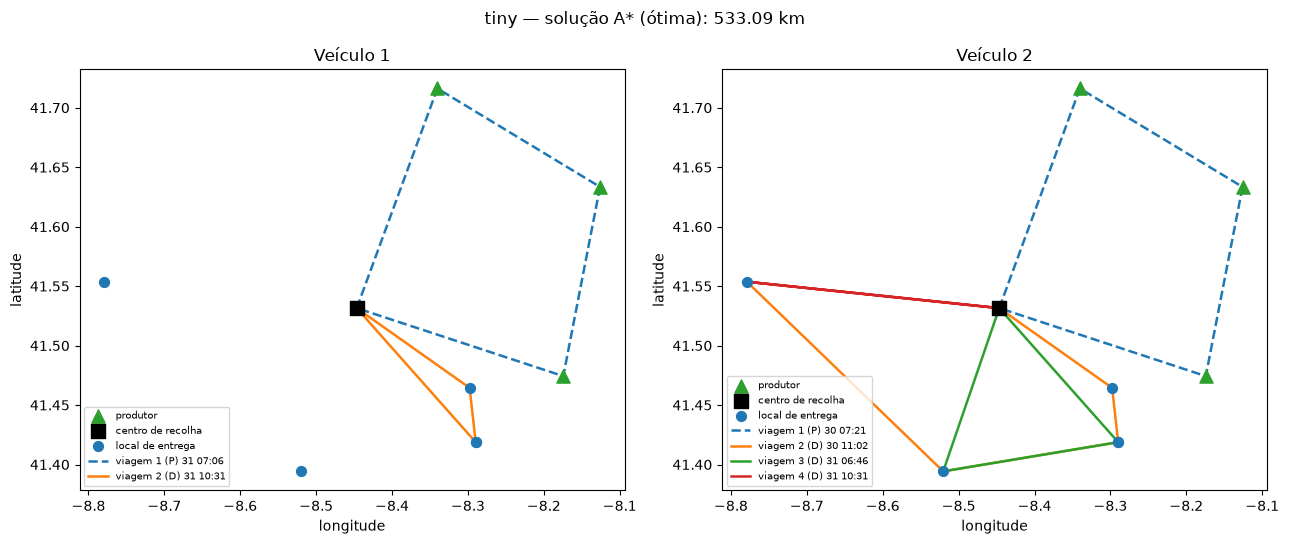

In [13]:
best_tiny = {int(k): v for k, v in json.loads((REPORTS / "solution_tiny_astar.json").read_text()).items()}
ev = evaluate(tiny, best_tiny)
print(ev.summary()); print("verificador por linha:", check_solution(tiny, ev).valid)
for v, trips in best_tiny.items():
    print(f"Veículo {v}:", " | ".join("W→" + "→".join(t) + "→W" for t in trips))
plot_routes(tiny, best_tiny, f"tiny — solução A* (ótima): {ev.km:.2f} km");

,vehicle,trip,stop,kind,arrival,start,window,weight
0,1,0,W,P,NaN,31 07:06,,NaN
1,1,0,P6,P,31 07:45,31 07:45,31 07:45-31 09:45,32.1
2,1,0,P4,P,31 08:29,31 08:29,31 08:15-31 10:00,29.9
3,1,0,P2,P,31 09:11,31 09:11,31 09:00-31 11:15,41.1
4,1,0,W,P,31 10:01,NaN,,NaN
5,1,1,W(load),D,NaN,31 10:31,,NaN
6,1,1,D1,D,31 11:03,31 11:03,31 10:30-31 12:45,22.0
7,1,1,D6,D,31 11:13,31 11:13,31 10:45-31 13:15,16.7
8,1,1,D7,D,31 11:23,31 11:23,31 10:45-31 13:30,33.5
9,1,1,D5,D,31 11:42,31 11:42,31 10:30-31 12:30,9.3


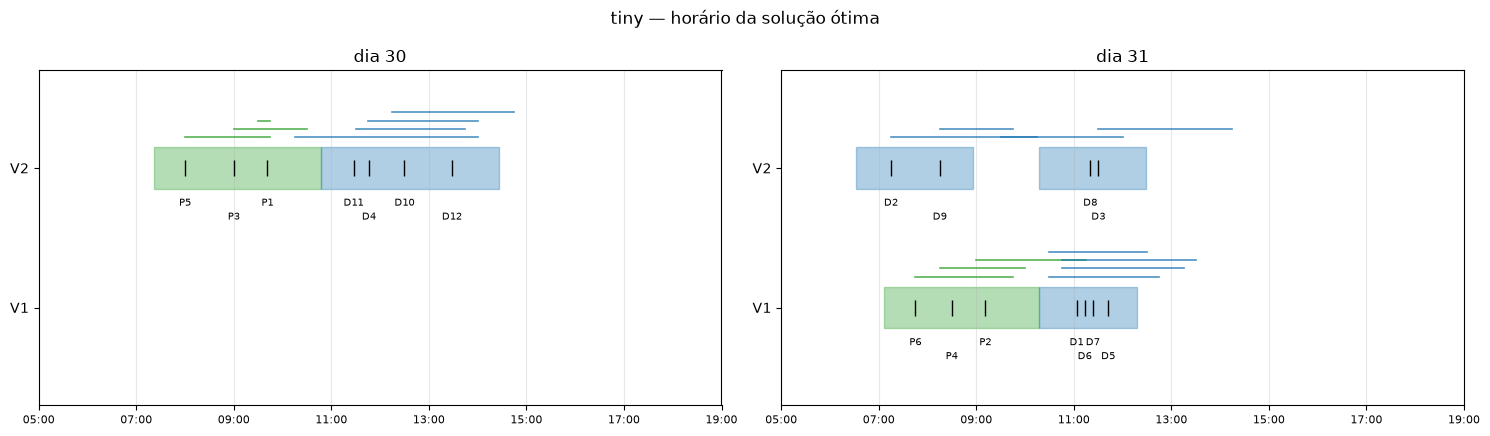

In [14]:
plot_gantt(tiny, ev, "tiny — horário da solução ótima");
schedule_table(tiny, ev)

**Análise**

* **A qualidade da heurística decide tudo.** No estado inicial do tiny, h1 vale 75,32 km
  (14% do ótimo), h3 vale 441,83 km (83%) e h4
  vale 533,09 km (100%). No A\* paragem a paragem do tiny:
  * h1: sem solução ao fim de 1 000 000 expansões (182 s);
  * h2: sem solução ao fim de 1 000 000 expansões (253 s);
  * h3: 533,09 km com 708 492 expansões (163 s);
  * h4: 533,09 km com 6 962 expansões (0,85 s).
* **A formulação viagem a viagem** reduz o espaço de pesquisa de forma radical:
  * tiny: o A\* com h4 dá 533,09 km com 7 expansões (0,01 s);
  * small: 757,84 km com 14 expansões (1,81 s). Paragem a paragem, mesmo com h4, o small fica sem solução ao fim de 150 000 expansões (61,98 s).

  O catálogo do small tem 272 062 ordens possíveis, reduzidas a
  4 067 opções pela dominância exata. Construir o catálogo demora 20–35 s e é feito uma vez.
* **Ótimos provados:** como as heurísticas são admissíveis e as podas exatas, **533,09 km é o
  ótimo do tiny** e **757,84 km é o ótimo do small**, dentro do
  modelo (pedidos agrupados, viagens homogéneas). No small, o valor da h4 no estado inicial
  (757,84 km) coincide com o ótimo: a relaxação já não deixa folga.
* **O Greedy é rápido mas não ótimo:** com h3 dá 625,46 km no tiny
  (17,3% acima do ótimo) e com h4 611,13 km (14,6% acima).
* **O A\* ponderado** (h3, paragem a paragem) com w = 1,5 dá 533,09 km com apenas
  152 expansões (sem garantia; o limite teórico é 1,5 × ótimo).
* **A solução ótima do tiny** usa 6 viagens:
  * veículo 1 (2 viagens): recolha às 07:06 do dia 31 (P6, P4, P2); entrega às 10:31 do dia 31 (D1, D6, D7, D5)
  * veículo 2 (4 viagens): recolha às 07:21 do dia 30 (P5, P3, P1); entrega às 11:02 do dia 30 (D11, D4, D10, D12); entrega às 06:46 do dia 31 (D2, D9); entrega às 10:31 do dia 31 (D8, D3)

  As encomendas D2 e D9, recolhidas na véspera, têm de chegar até às 10:15 e às 09:45 do dia 31. Nessa
  altura as recolhas desse dia ainda não voltaram ao armazém, por isso seguem numa viagem própria de
  manhã cedo.

## 5. Pesquisa local

Experiências detalhadas em [`04_local_search.ipynb`](04_local_search.ipynb).

**Representação:** uma solução completa `{veículo: [viagens]}`. **Vizinhança**, em que cada movimento
mantém as viagens homogéneas:

* *relocate*: tirar um pedido e inseri-lo noutra posição, viagem ou veículo, ou numa viagem nova;
* *swap*: trocar dois pedidos do mesmo tipo;
* *2-opt*: inverter um segmento dentro de uma viagem.

**Função objetivo:** o custo penalizado (km + penalizações).

* **Hill Climbing, *steepest*:** avalia a vizinhança toda e escolhe o melhor vizinho viável; para num
  ótimo local.
* **Hill Climbing, *first improvement*:** percorre a vizinhança numa ordem aleatória e aceita o primeiro
  vizinho viável que melhora.
* **Simulated Annealing:** escolhe um vizinho aleatório e aceita-o com probabilidade exp(−Δ/T), com
  arrefecimento geométrico (T₀ = 30, α = 0,9998, 30 000 iterações). Pode passar por soluções inviáveis,
  mas devolve a melhor solução **viável** que visitou.

Em todos os casos o ponto de partida é a solução **Greedy (h3)**.

In [15]:
start = res["h3_mst"].solution
hc_s = hill_climbing(tiny, start, "steepest")
hc_f = hill_climbing(tiny, start, "first", seed=0)
sa = simulated_annealing(tiny, start, t0=30, alpha=0.9998, iters=30_000, seed=0)
pd.DataFrame([hc_s.summary(), hc_f.summary(), sa.summary()])

,algorithm,initial_km,final_km,improvement_pct,feasible,iterations,evaluated,seconds
0,HC-steepest,625.46,533.09,14.77,True,5,2714,0.132
1,HC-first,625.46,533.09,14.77,True,5,705,0.131
2,SA,625.46,533.09,14.77,True,30000,30000,1.522


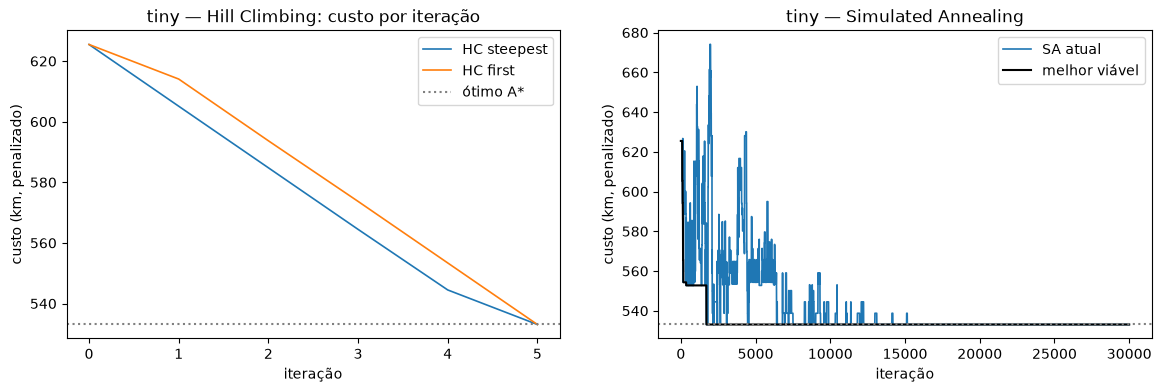

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
plot_histories({"HC steepest": dict(current=hc_s.history), "HC first": dict(current=hc_f.history)},
               "tiny — Hill Climbing: custo por iteração", ax=ax[0])
ax[0].axhline(evaluate(tiny, best_tiny).km, color="grey", ls=":", label="ótimo A*"); ax[0].legend()
plot_histories({"SA atual": dict(current=sa.history)}, "tiny — Simulated Annealing", ax=ax[1], cap=800)
ys = pd.Series(sa.best_history).replace(float("inf"), None)
ax[1].plot(ys.index, ys.values, color="black", lw=1.5, label="melhor viável"); ax[1].legend()
ax[1].axhline(evaluate(tiny, best_tiny).km, color="grey", ls=":");

In [17]:
print("movimentos aceites pelo HC steepest:")
for m in hc_s.moves:
    print("  ", m)

movimentos aceites pelo HC steepest:
   ('relocate', 'P6', 1, 0, 0)
   ('relocate', 'P2', 1, 0, 2)
   ('relocate', 'P1', 2, 0, 2)
   ('swap', 'D10', 'D11')
   ('relocate', 'D5', 1, 1, 0)


In [18]:
local = pd.read_csv(REPORTS / "local.csv")
local.groupby(["dataset", "algorithm"]).agg(km_min=("final_km", "min"), km_media=("final_km", "mean"),
    km_max=("final_km", "max"), segundos=("seconds", "mean"), avaliacoes=("evaluated", "mean"), corridas=("seed", "count")).round(2)

km_min  km_media  km_max  segundos  avaliacoes  corridas
dataset algorithm                                                            
small   HC-first     799.35    817.06  834.22      0.51      4030.2         5
        HC-steepest  799.35    799.35  799.35      1.08     15904.0         1
        SA           771.69    801.54  821.94      2.46     30000.0         5
tiny    HC-first     533.09    533.09  533.09      0.05       821.8         5
        HC-steepest  533.09    533.09  533.09      0.11      2714.0         1
        SA           533.09    533.09  533.09      1.21     30000.0         5

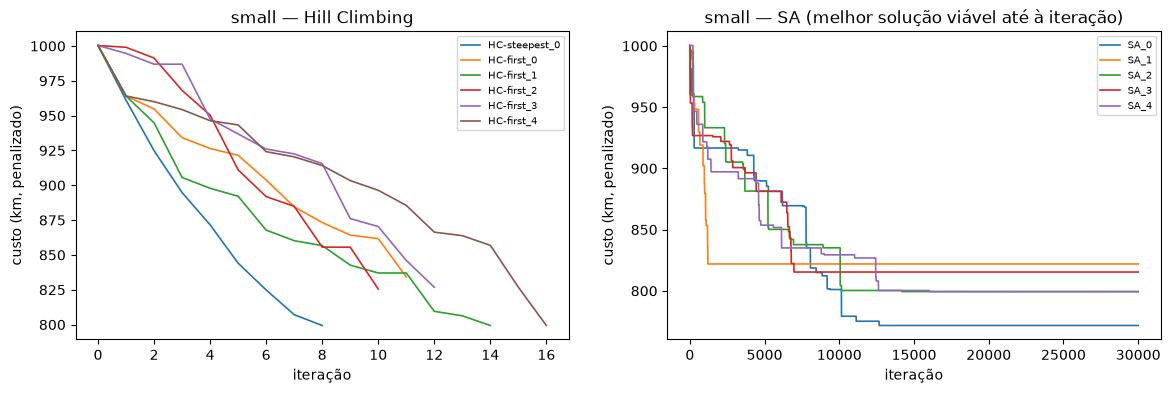

In [19]:
hist = json.loads((REPORTS / "local_histories.json").read_text())
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
plot_histories({k: v for k, v in hist["small"].items() if k.startswith("HC")}, "small — Hill Climbing", ax=ax[0])
plot_histories({k: dict(current=[x if x != float("inf") else None for x in v["best"]]) for k, v in hist["small"].items()
                if k.startswith("SA")}, "small — SA (melhor solução viável até à iteração)", ax=ax[1]);

**Análise**

* **No tiny**, os três métodos partem da solução Greedy (625,46 km) e chegam
  todos ao **ótimo de 533,09 km**. O HC *steepest* precisa de 5 iterações
  (0,11 s). O A\* paragem a paragem com h3 precisou de quase 3 minutos para provar que este valor é o
  ótimo (com h4, ou por viagens, menos de 1 s). Os
  movimentos aceites foram 4× relocate, 1× swap.
* **No small**:
  * o HC *steepest* melhora a solução Greedy de 1000,35 para
    799,35 km, 5,5% acima do ótimo provado (757,84 km);
  * o HC *first* termina entre 799,35 e 834,22 km
    (5 sementes), porque a ordem aleatória leva a ótimos locais diferentes;
  * o SA chega a 771,69–821,94 km (5 sementes, a melhor 1,8% acima do ótimo). A melhor corrida fica abaixo do HC: o SA aceita pioras temporárias e escapa a ótimos locais em que o HC fica preso. Em média, porém (801,54 km), o SA não bate o HC *steepest*: só 1 das 5 sementes fica abaixo dele.
* **Custo:** o HC *steepest* avalia a vizinhança inteira em cada iteração (cerca de 540 vizinhos no
  tiny e 2 000 no small). O *first improvement* é mais barato por iteração e, no small, faz mais
  iterações (10–16 contra 8). O SA tem custo fixo (30 000 avaliações).

## 6. CSP — problema de satisfação de restrições

Experiências detalhadas em [`05_csp.ipynb`](05_csp.ipynb).

### 6.1 Formulação

* **Variáveis:** uma por pedido, X_r para r ∈ {recolhas} ∪ {entregas}. São 18 no tiny e 37 no small.
* **Domínio:** D(X_r) = {(veículo, dia, posição)}. Cada dia tem um modelo fixo de posições de viagem,
  `D-P-D-D-P-D-D` (D = viagem de entrega, P = viagem de recolha). Os pedidos com o mesmo valor formam uma
  viagem, visitada pela permutação mais curta que cumpre as janelas.
* **Restrições unárias:** o tipo da posição tem de ser igual ao tipo do pedido, e o dia da posição igual
  ao dia da janela (nenhuma viagem atravessa a meia-noite).
* **Restrições binárias**, usadas pelo forward checking e pelo AC-3:
  * mesma viagem ⇒ w_a + w_b ≤ capacidade do veículo;
  * mesma viagem ⇒ os dois pedidos podem seguir-se um ao outro dentro das janelas e, nas entregas, os
    produtos de um não ficam prontos tarde demais para o outro;
  * entrega e uma das suas recolhas no mesmo veículo ⇒ a viagem da recolha vem antes;
  * mesmo veículo, viagem de a antes da de b ⇒ b continua alcançável depois de a voltar ao armazém
    (sequência).
* **Restrições globais:** capacidade de cada viagem (n-ária) e um **horário completo viável**. O horário
  inclui janelas, precedência entre veículos através do armazém, permanência ≤ 24 h e ausência de
  bloqueios. É verificado pelo simulador sobre a atribuição parcial.
* **Restrição suave:** minimizar os km. Não pode ser violada, só otimizada.

### 6.2 Algoritmos e heurísticas

* **Backtracking** com ordem das variáveis *estática* ou **MRV** (menor domínio restante, desempate
  pelo grau).
* **Ordenação dos valores *soft*:** é a heurística que trata a restrição suave. Prefere o valor que menos
  km acrescenta (inserção mais barata numa viagem existente; abrir uma viagem nova tem uma penalização).
  Em caso de empate prefere o valor que menos valores tira aos vizinhos (*least constraining value*).
* **Inferência:**
  * nenhuma;
  * **forward checking** (FC) sobre as restrições binárias;
  * **MAC**: FC seguido de **AC-3**;
  * opcionalmente, FC contra a restrição **global** (`global_fc`), que retira dos domínios os valores
    que já tornam o horário inviável.
* **Branch & bound** (opcional): depois da primeira solução, continua a procurar com o limite
  km(parcial) < melhor km. É válido porque acrescentar pedidos nunca reduz os km.

In [20]:
csp_t = RoutingCSP(tiny)
print("variáveis:", len(csp_t.vars), "| valores iniciais:", sum(map(len, csp_t.domains.values())),
      "| pares com restrição binária:", sum(map(len, csp_t.neigh.values())) // 2)
print("domínio de D2:", csp_t.domains["D2"])

variáveis: 18 | valores iniciais: 144 | pares com restrição binária: 149
domínio de D2: [(1, 1, 0), (1, 1, 2), (1, 1, 3), (1, 1, 5), (1, 1, 6), (2, 1, 0), (2, 1, 2), (2, 1, 3), (2, 1, 5), (2, 1, 6)]


In [21]:
rows = []
for inference in ("none", "fc", "mac"):
    for gfc in (False, True):
        r = solve(tiny, inference=inference, global_fc=gfc)
        rows.append(r.summary())
pd.DataFrame(rows)

,inference,var_order,value_order,global_fc,optimize,status,cost_km,assignments,backtracks,checks,pruned,solutions,seconds
0,none,mrv,soft,False,False,feasible,659.27,25,7,26,0,1,0.007
1,none,mrv,soft,True,False,feasible,662.47,18,0,1255,62,1,0.031
2,fc,mrv,soft,False,False,feasible,659.27,21,3,22,37,1,0.003
3,fc,mrv,soft,True,False,feasible,662.47,18,0,1203,62,1,0.040
4,mac,mrv,soft,False,False,feasible,659.27,21,3,22,37,1,0.015
5,mac,mrv,soft,True,False,feasible,662.47,18,0,1176,66,1,0.068


In [22]:
csp_res = pd.read_csv(REPORTS / "csp.csv")
csp_res[~csp_res.optimize].pivot_table(index=["inference", "var_order", "value_order"], columns=["dataset", "global_fc"],
                                       values="backtracks", aggfunc="first")

dataset                          small        tiny      
global_fc                        False True  False True 
inference var_order value_order                         
fc        mrv       soft             1     1     3     0
                    static           5     0     3     0
          static    soft            21     5     7     0
                    static           4     0     3     0
mac       mrv       soft             0     0     3     0
                    static           5     0     3     0
          static    soft            20     4     7     0
                    static           4     0     3     0
none      mrv       soft            20     1     7     0
                    static           4     0     3     0
          static    soft         19976     5     7     0
                    static           4     0     3     0

In [23]:
csp_res[~csp_res.optimize].pivot_table(index=["inference", "var_order", "value_order"], columns=["dataset", "global_fc"],
                                       values="cost_km", aggfunc="first")

dataset                           small            tiny        
global_fc                         False   True    False   True 
inference var_order value_order                                
fc        mrv       soft         825.85  860.72  659.27  662.47
                    static       872.98  901.58  659.27  700.17
          static    soft         931.69  966.56  659.27  680.50
                    static       846.54  875.14  659.27  680.50
mac       mrv       soft         825.85  860.72  659.27  662.47
                    static       872.98  901.58  659.27  700.17
          static    soft         931.69  966.56  659.27  680.50
                    static       846.54  875.14  659.27  680.50
none      mrv       soft         931.69  860.72  659.27  662.47
                    static       846.54  901.58  659.27  700.17
          static    soft            NaN  966.56  659.27  680.50
                    static       846.54  875.14  659.27  680.50

In [24]:
csp_res[csp_res.optimize]

,dataset,inference,var_order,value_order,global_fc,optimize,status,cost_km,assignments,backtracks,checks,pruned,solutions,seconds,feasible,item_check,km_check
24,tiny,mac,mrv,soft,True,True,best found (limit),641.24,20000,19987,485578,8617,3,23.552,True,True,641.24
49,small,mac,mrv,soft,True,True,best found (limit),840.04,20000,19971,378056,29290,3,34.711,True,True,840.04


**Análise**

* **No tiny**, as 24 combinações encontram uma atribuição viável, com poucos backtracks (no máximo 7;
  3 com MAC + MRV + *soft*). Com o FC global, nenhuma precisa de backtracks.
* **No small** a inferência faz diferença quando a ordem dos valores é *soft*:
  * ordem estática das variáveis: sem inferência, sem solução após 20 000 atribuições; com forward
    checking, 931,69 km com 21 backtracks; com MAC, 931,69 km com 20 backtracks;
  * MRV: sem inferência, 931,69 km com 20 backtracks; com forward checking, 825,85 km com 1 backtrack;
    com MAC, 825,85 km com 0 backtracks.

  A restrição binária de **sequência** (no mesmo veículo, a viagem que vem depois tem de continuar
  alcançável) é a que deixa o FC podar: retira dos pedidos ainda por atribuir as viagens que já não
  cabem no horário. Sem inferência, a ordem *soft* tenta encher primeiro as viagens existentes, e o
  backtracking só descobre o erro muito mais abaixo na árvore (*thrashing*). Com a ordem estática dos
  valores, as 6 combinações resolvem o small com 4–5 backtracks.
* **AC-3 na raiz** não remove valores: cada pedido tem sempre um valor compatível noutra viagem ou
  noutro veículo. O AC-3 só ganha força durante a pesquisa (MAC), quando os domínios já estão reduzidos.
* **Com o FC global** (o simulador como filtro), as 12 combinações resolvem o small com no máximo 5
  backtracks. Com MAC + MRV + *soft*, foram 0,26 s, 0 backtracks e 860,72 km. Cada nó fica mais caro
  (5 004 verificações do horário), mas a árvore fica mínima. Em troca, a primeira solução tem mais km
  (860,72 contra 825,85 no small; 662,47 contra 659,27 no tiny): a filtragem muda os domínios e, com
  eles, a escolha da ordenação *soft* (que desempata pelo *least constraining value*).
* **O branch & bound** parte da solução MAC + MRV + *soft* + FC global e melhora-a de 662,47 para
  641,24 km (tiny) e de 860,72 para 840,04 km (small), com 3 soluções em cada caso. Esgota o orçamento
  de 20 000 atribuições sem provar o ótimo.
* **Os km do CSP ficam acima da pesquisa local** porque o CSP procura **viabilidade**: os km só entram
  pela ordenação de valores. É também uma forma rápida de obter um primeiro horário viável, que pode
  servir de ponto de partida para a pesquisa local.

## 7. Análise de resultados

In [25]:
rows = []
for ds in ("tiny", "small"):
    for alg in ["Greedy", "A*", "WA*(w=1.5)", "WA*(w=2.0)", "A*-viagens"]:
        for h in ("h1_max_detour", "h2_min_arcs", "h3_mst", "h4_relaxed"):
            m = informed[(informed.dataset == ds) & (informed.algorithm == alg) & (informed.heuristic_name == h)]
            if len(m):
                r = m.iloc[0]
                rows.append(dict(dataset=ds, metodo=f"{alg} {h.split('_')[0]}", km=r.cost_km, segundos=r.seconds,
                                 esforco=f"{int(r.expanded)} expansões", completo=r.complete))
    for alg in ("HC-steepest", "HC-first", "SA"):
        d = local[(local.dataset == ds) & (local.algorithm == alg)]
        rows.append(dict(dataset=ds, metodo=alg + " (melhor de %d)" % len(d), km=d.final_km.min(), segundos=d.seconds.mean(),
                         esforco=f"{int(d.evaluated.mean())} avaliações", completo=None))
    base = (csp_res.var_order == "mrv") & (csp_res.value_order == "soft") & ~csp_res.optimize
    for label, mask in [("CSP FC+MRV+soft", base & (csp_res.inference == "fc") & ~csp_res.global_fc),
                        ("CSP MAC+MRV+soft", base & (csp_res.inference == "mac") & ~csp_res.global_fc),
                        ("CSP MAC+MRV+soft+FC global", base & (csp_res.inference == "mac") & csp_res.global_fc),
                        ("CSP branch & bound", csp_res.optimize)]:
        r = csp_res[(csp_res.dataset == ds) & mask].iloc[0]
        rows.append(dict(dataset=ds, metodo=label, km=r.cost_km, segundos=r.seconds,
                         esforco=f"{int(r.backtracks)} backtracks", completo=None))
comparison = pd.DataFrame(rows)
comparison.round(2)

,dataset,metodo,km,segundos,esforco,completo
0,tiny,Greedy h1,707.16,0.00,44 expansões,True
1,tiny,Greedy h2,674.14,0.00,29 expansões,True
2,tiny,Greedy h3,625.46,0.00,29 expansões,True
3,tiny,Greedy h4,611.13,0.01,28 expansões,True
4,tiny,A* h1,NaN,181.78,1000000 expansões,False
5,tiny,A* h2,NaN,253.38,1000000 expansões,False
6,tiny,A* h3,533.09,162.86,708492 expansões,True
7,tiny,A* h4,533.09,0.84,6962 expansões,True
8,tiny,WA*(w=1.5) h3,533.09,0.08,152 expansões,True
9,tiny,WA*(w=2.0) h3,553.08,0.02,56 expansões,True


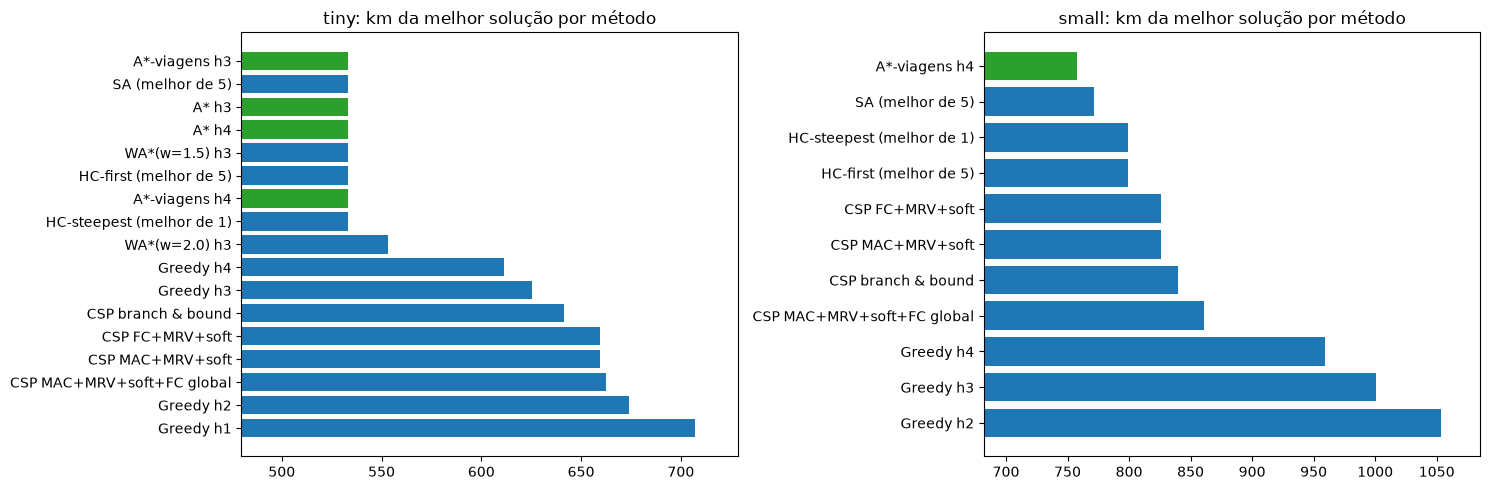

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for a_, ds in zip(ax, ("tiny", "small")):
    d = comparison[(comparison.dataset == ds) & comparison.km.notna()].sort_values("km")
    a_.barh(d.metodo, d.km, color=["tab:green" if m.startswith("A*") else "tab:blue" for m in d.metodo])
    a_.set_xlim(d.km.min() * 0.9, d.km.max() * 1.03)
    a_.set_title(f"{ds}: km da melhor solução por método"); a_.invert_yaxis()
fig.tight_layout()

### 7.1 Melhor solução do small

{'tiny': {'km': 533.09, 'source': 'A*_h3_mst'}, 'small': {'km': 757.84, 'source': 'A*-viagens_h4_relaxed'}}
{'km': 757.84, 'feasible': True, 'trips': 6, 'late_min': 0.0, 'over_kg': 0.0, 'dwell_excess_min': 0.0, 'unserved': 0, 'deadlock': 0, 'overnight': 0, 'makespan_min': 2515.7, 'route_min': 1466.7}
verificador por linha: True
Veículo 1: W→P9→W | W→D15→D16→D6→D18→D19→D1→D9→D2→W | W→D23→D5→D25→D14→D11→D17→W
Veículo 2: W→P7→P11→P1→P3→P5→W | W→P8→P12→P2→P4→P6→P10→W | W→D7→D21→D24→D10→D22→D13→D8→D12→D3→D20→D4→W


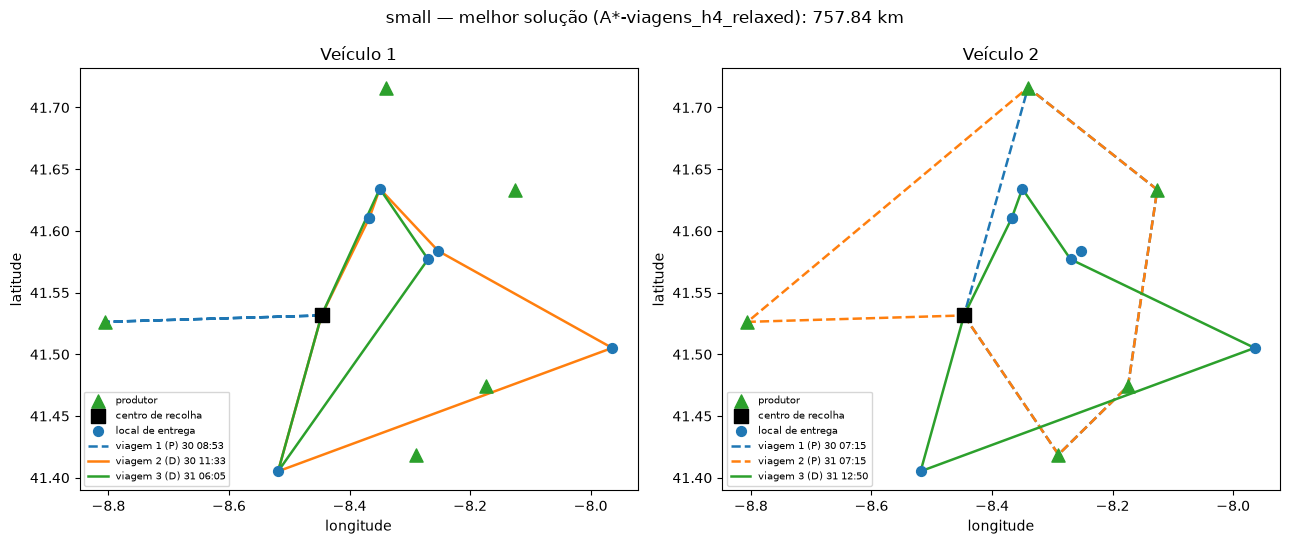

In [27]:
best = json.loads((REPORTS / "best.json").read_text()); print(best)
best_small = {int(k): v for k, v in json.loads((REPORTS / "solution_small_best.json").read_text()).items()}
ev_s = evaluate(small, best_small)
print(ev_s.summary()); print("verificador por linha:", check_solution(small, ev_s).valid)
for v, trips in best_small.items():
    print(f"Veículo {v}:", " | ".join("W→" + "→".join(t) + "→W" for t in trips))
plot_routes(small, best_small, f"small — melhor solução ({best['small']['source']}): {ev_s.km:.2f} km");

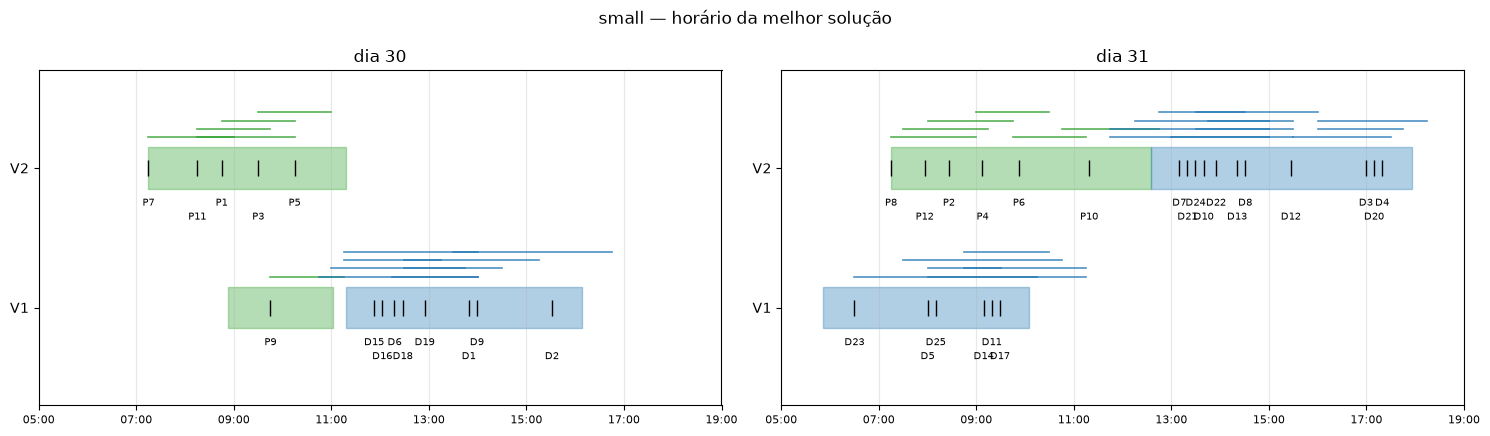

In [28]:
plot_gantt(small, ev_s, "small — horário da melhor solução");

### 7.2 Análise crítica

**Qualidade das soluções**

* **Tiny:** o ótimo é **533,09 km**, provado pelo A\*. O HC e o A\* ponderado com w = 1,5 chegam lá
  em décimas de segundo, e o SA em cerca de 1,2 s. O Greedy (h3) fica 17,3% acima, a primeira solução
  do CSP (MAC + MRV + *soft*) 23,7% acima e o branch & bound 20,3% acima.
* **Small:** o ótimo é **757,84 km**, provado pelo A\* por viagens com h4 em 14 expansões. A pesquisa local fica entre 1,8% e 10,1% acima. O melhor CSP (FC ou MAC + MRV + *soft*, 825,85 km) fica 9,0% acima, e o branch & bound 10,8%.
  O A\* paragem a paragem não termina no orçamento, nem com h4: a escolha das **ações** (paragem
  vs. viagem) pesa tanto como a heurística.

**Tempos de execução** (uma execução num portátil, com variação entre máquinas)

* Greedy: milissegundos no tiny; até 0,85 s no small (h4).
* A\* paragem a paragem: minutos no tiny (h3); não termina no small.
* A\* por viagens (h4): centésimas de segundo no tiny; cerca de 2 s no small, mais a construção do
  catálogo de viagens (20–35 s, feita uma vez).
* HC: centésimas a décimas de segundo no tiny; 0,4–1,1 s no small.
* SA (30 000 iterações): cerca de 1,2 s no tiny e 2–2,6 s no small.
* CSP: centésimas de segundo com FC/MAC; 0,15–0,28 s com o FC global no small; o branch & bound gasta
  o orçamento (24–35 s).

**Comparação entre famílias**

* **A pesquisa informada** dá garantias (ótimo, completude). Escala mal se a heurística for fraca ou as
  ações forem demasiado finas, mas com uma relaxação exata (h4) e ações ao nível da viagem prova o ótimo
  dos dois datasets em segundos. O Greedy é a forma mais barata de obter uma primeira solução.
* **A pesquisa local** não dá garantias, mas, partindo de uma solução razoável, chega a 0–10% do ótimo
  em menos de 3 s e escalaria para instâncias maiores. Nestes dois datasets, porém, o A\* por viagens com h4 é
  ainda melhor: prova o ótimo em 0,01 s (tiny) e em cerca de 20–40 s (small, incluindo o catálogo).
* **O CSP** é a forma natural de exprimir as restrições: a viabilidade é o centro do problema. A
  inferência (FC/MAC) só compensa com restrições binárias que capturem a estrutura temporal (a
  sequência). O FC contra a restrição global elimina praticamente o backtracking (no máximo 5
  backtracks no small), à custa de mais verificações e de primeiras soluções com mais km.

**Limitações do modelo**

* As recolhas são agrupadas pela interseção das janelas. Isto pode excluir soluções em que o mesmo
  produtor é visitado em dois momentos para linhas diferentes.
* As viagens são homogéneas. Uma viagem mista (entregar em Guimarães e recolher em Fafe no regresso)
  pouparia km, mas complica a precedência.
* O modelo de posições do CSP fixa o número máximo de viagens por dia.
* A partida *just in time* não procura atrasar recolhas para reduzir a permanência no armazém.

**Melhorias futuras**

1. **Viagens mistas** (entrega + recolha na mesma volta), com a precedência tratada ao nível da linha.
2. **Recolhas parciais** em vez da interseção das janelas, com o agrupamento decidido pela pesquisa.
3. **Escalar o A\* por viagens** para datasets maiores: o catálogo cresce com o número de pedidos por
   grupo. Ajudariam gerar as viagens por *column generation* e acrescentar à h4 o limite de 2 veículos.
4. **Mais vizinhança na pesquisa local** (troca de viagens inteiras entre veículos, *or-opt*), e
   **pesquisa local iterada**.
5. **CSP com tempos como variáveis** e propagação temporal (STN), e CP-SAT para instâncias grandes.
6. **Objetivos múltiplos:** km, tempo de condução, equilíbrio entre veículos, emissões; e uso da
   refrigeração quando houver dados sobre os produtos.

## 8. Conclusão

O agente desenvolvido planeia recolhas e entregas que cumprem todas as regras do problema: janelas,
capacidade, passagem pelo armazém com permanência máxima, e serviço e manuseamento. Cada solução é
confirmada por um verificador independente, linha a linha, que trabalha diretamente sobre os CSV.

**Resultados:** provámos o ótimo dos dois datasets (533,09 km no tiny, 757,84 km no small).

**Algoritmos:**

* **A pesquisa informada** mostrou o peso da heurística e da formulação. Da h1 à h4 o número de nós
  expandidos cai várias ordens de grandeza. Mudar as ações de "uma paragem" para "uma viagem" tornou o
  small resolúvel de forma exata.
* **A pesquisa local** melhora depressa uma solução inicial (até 22,9% no small) e é a abordagem que
  melhor escalaria para instâncias maiores, mas não garante o ótimo.
* **O CSP**, formulado com atribuição de pedidos a viagens, mostrou a diferença entre propagar
  restrições fracas e propagar restrições que capturam a estrutura temporal (sequência e horário global).

**Desenvolvimento:**

* Começámos com uma análise exploratória que orientou as decisões de modelação: agrupar recolhas, uma
  paragem por encomenda, viagens homogéneas.
* Separámos o código em módulos (`model`, `informed`, `local_search`, `csp`), com testes
  unitários e um script que reproduz todas as experiências.
* Ferramentas: Python 3, pandas, matplotlib e Jupyter.

O principal obstáculo foi a interação entre veículos através do armazém, que obrigou a uma simulação
dirigida por dependências e a podas cuidadosas (dominância, ordens de viagem) para manter o A\* exato.